In [7]:
!pip install -q ultralytics

In [8]:
import ultralytics

print(ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
8.4.216


In [9]:
!cat /content/dataset/data.yaml

path: /content/dataset
train: images/train
val: images/val
test: images/test
nc: 3
names:
  0: person
  1: apple
  2: vehicle


In [10]:
from ultralytics import YOLO

# 사전 학습된 YOLOv8 Nano 모델 불러오기
model = YOLO("yolov8n.pt")

# Fine-tuning
results = model.train(
    data="/content/dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/runs",
    name="person_apple_vehicle",
    plots=True
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=person_apple_vehicle, nbs=64, nms=None, opset=None, optimize=F

In [12]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/runs/person_apple_vehicle/weights/best.pt"
)

metrics = best_model.val(
    data="/content/dataset/data.yaml",
    split="test",
    device=0
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1482.0±691.7 MB/s, size: 62.0 KB)
val: Scanning /content/dataset/labels/test... 32 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 32/32 1.9Kit/s 0.0s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s
                   all         32        194      0.759      0.743      0.766      0.543
                person          9        152      0.714      0.395      0.533      0.208
                 apple         10         12      0.833          1      0.925      0.841
               vehicle         13         30       0.73      0.833      0.841      0.579
Speed: 2.7ms preprocess, 6.9ms inference, 0.0ms loss, 1.8ms postprocess per image
Results s

In [14]:
from google.colab import files

files.download(
    "/content/runs/person_apple_vehicle/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
!find /content/runs -name "best.pt"

/content/runs/person_apple_vehicle/weights/best.pt


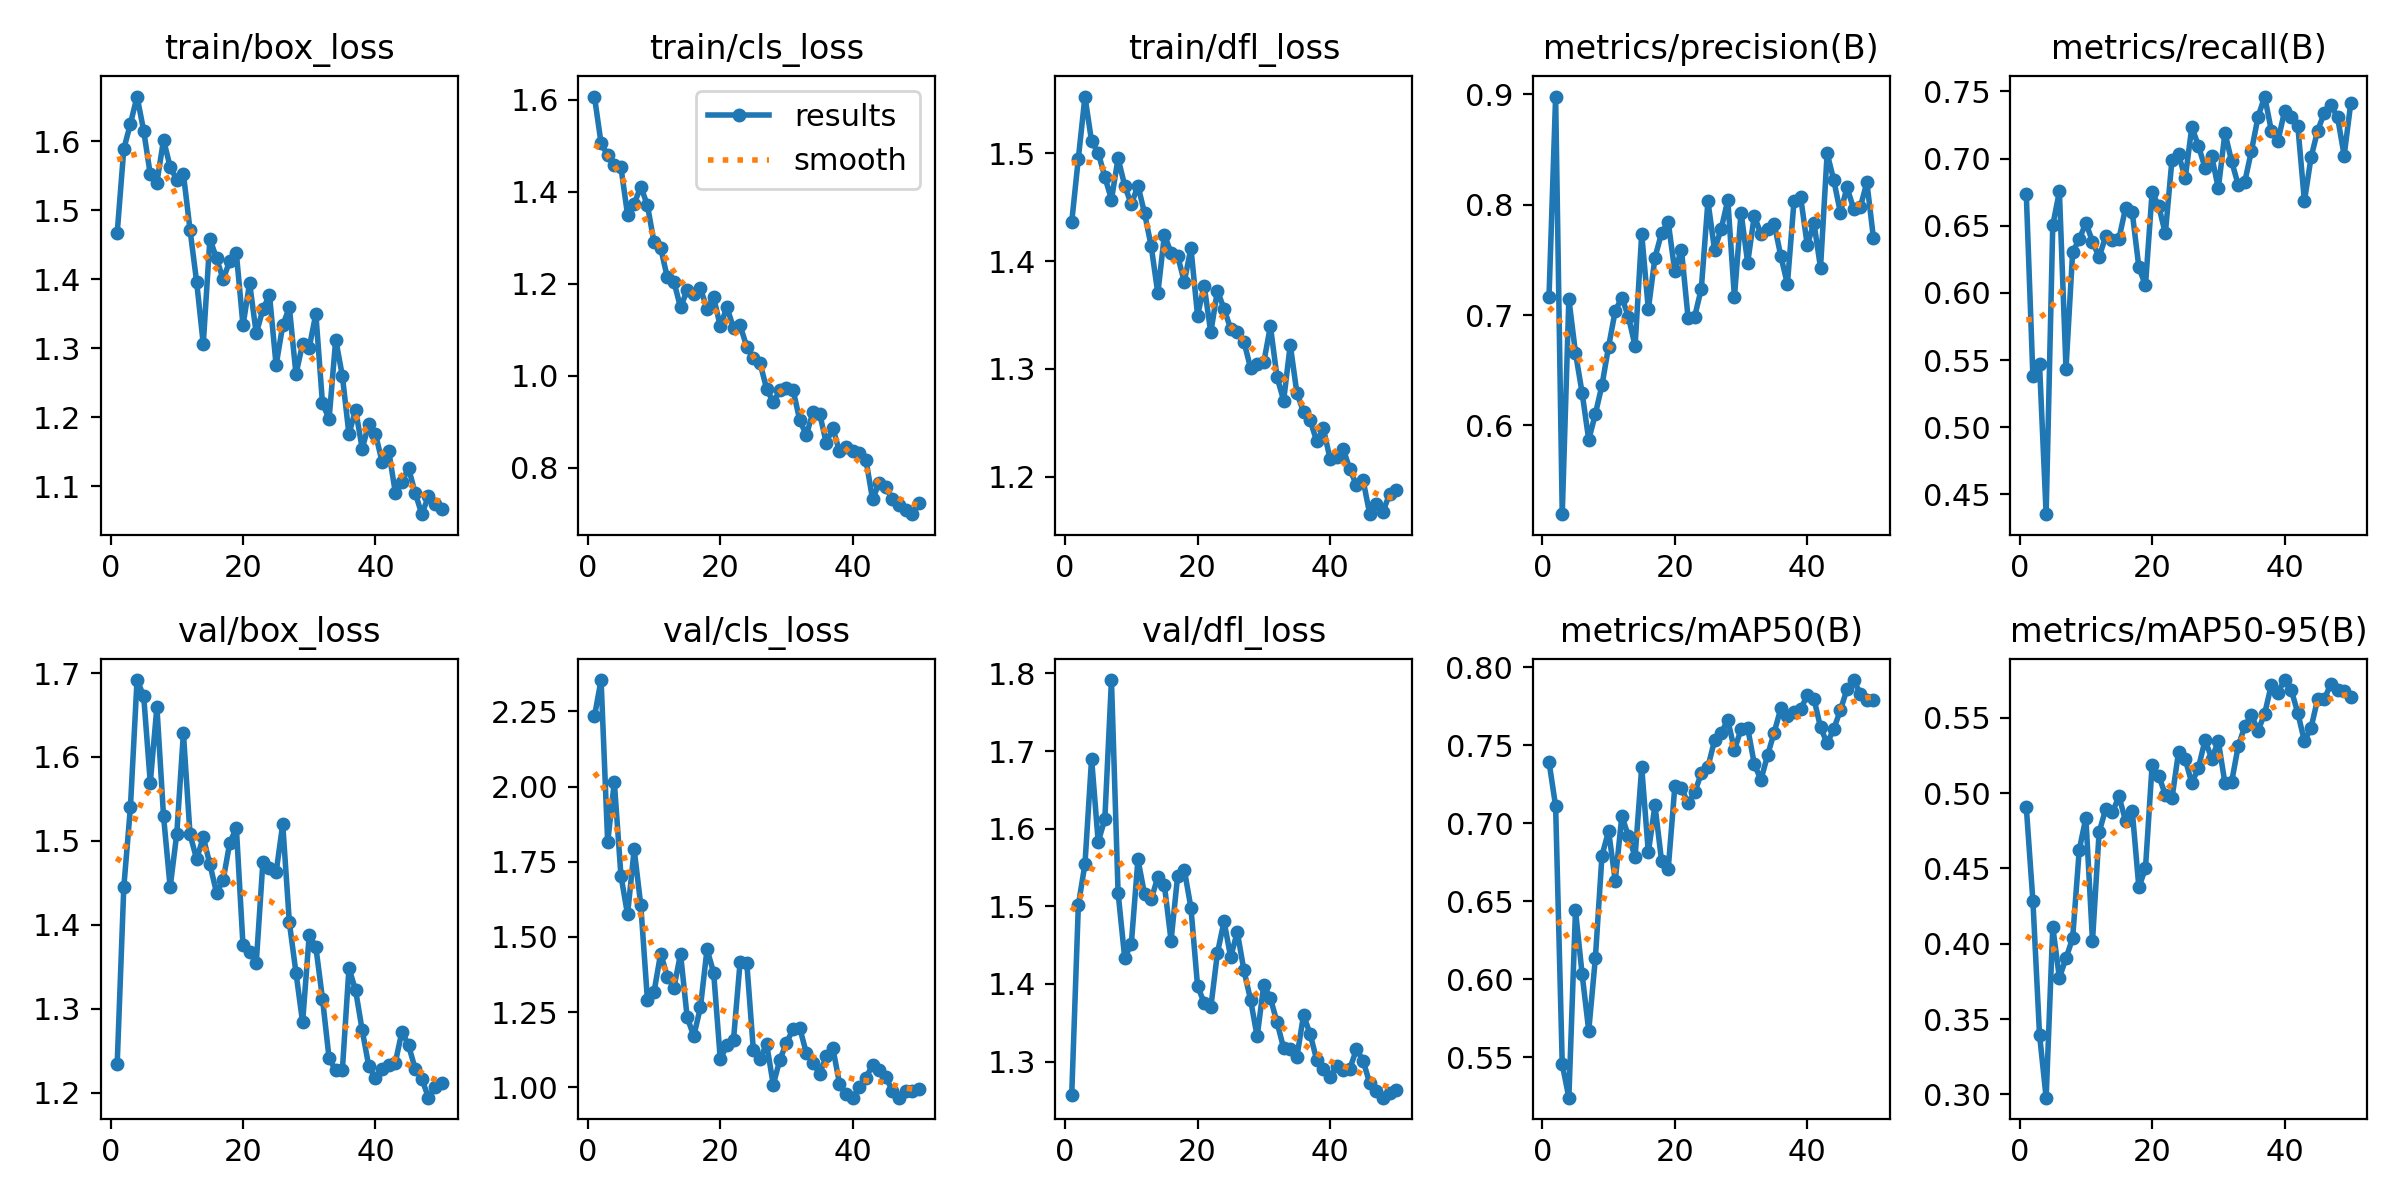

In [16]:
from IPython.display import Image, display

display(Image(
    filename="/content/runs/person_apple_vehicle/results.png"
))

In [17]:
best_model = YOLO(
    "/content/runs/person_apple_vehicle/weights/best.pt"
)

In [18]:
metrics = best_model.val(
    data="/content/dataset/data.yaml",
    split="test"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 311.9±219.7 MB/s, size: 13.6 KB)
val: Scanning /content/dataset/labels/test.cache... 32 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 32/32 2.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1s/it 2.1s
                   all         32        194      0.759      0.743      0.766      0.543
                person          9        152      0.714      0.395      0.533      0.208
                 apple         10         12      0.833          1      0.925      0.841
               vehicle         13         30       0.73      0.833      0.841      0.579
Speed: 6.4ms preprocess, 6.4ms inference, 0.0ms loss, 5.5ms postprocess per image
Results saved to /content/runs/detect/val-2
Precision: 0.758969

In [19]:
!find /content -name best.pt -type f

/content/runs/person_apple_vehicle/weights/best.pt


In [20]:
from google.colab import files

uploaded = files.upload()  # 원본 영상 파일 하나 선택
SOURCE_VIDEO = "/content/" + next(iter(uploaded))

Saving test-video.mp4 to test-video.mp4


In [22]:
import subprocess
from pathlib import Path

import cv2
from ultralytics import YOLO

WEIGHTS = Path("/content/runs/detect/train/weights/best.pt")
START_SEC = 0

CLIP = "/content/input_5s.mp4"
TEMP_VIDEO = "/content/tracking_temp.mp4"
OUTPUT = "/content/tracking_5s.mp4"

assert WEIGHTS.is_file(), f"best.pt 경로를 확인하세요: {WEIGHTS}"

subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-ss", str(START_SEC), "-i", SOURCE_VIDEO,
    "-t", "5", "-vf", "fps=30", "-an", "-c:v", "libx264", CLIP
], check=True)

model = YOLO(str(WEIGHTS))
print("모델의 클래스:", model.names)

writer = None
frame_count = 0
track_counts = {}

try:
    for result in model.track(
        source=CLIP, stream=True, tracker="bytetrack.yaml",
        device=0, verbose=False
    ):
        frame = result.plot()
        if writer is None:
            height, width = frame.shape[:2]
            writer = cv2.VideoWriter(
                TEMP_VIDEO, cv2.VideoWriter_fourcc(*"mp4v"),
                30, (width, height)
            )
            if not writer.isOpened():
                raise RuntimeError("영상 파일을 열 수 없습니다.")

        writer.write(frame)
        frame_count += 1

        if result.boxes.id is not None:
            for class_id, track_id in zip(
                result.boxes.cls.int().tolist(),
                result.boxes.id.int().tolist()
            ):
                track_counts.setdefault(model.names[class_id], set()).add(track_id)
finally:
    if writer is not None:
        writer.release()

assert frame_count == 150, (
    f"{frame_count}프레임만 처리됐습니다. "
    "선택한 시작점부터 원본 영상이 5초 이상 남아 있는지 확인하세요."
)

subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error", "-i", TEMP_VIDEO,
    "-c:v", "libx264", "-pix_fmt", "yuv420p",
    "-crf", "23", "-movflags", "+faststart", OUTPUT
], check=True)

print("추적 ID 개수:", {name: len(ids) for name, ids in track_counts.items()})
print(f"저장 완료: {OUTPUT} ({frame_count / 30:.1f}초)")

모델의 클래스: {0: 'person', 1: 'apple', 2: 'vehicle'}
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 343ms
Prepared 1 package in 25ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

추적 ID 개수: {'person': 4, 'vehicle': 3}
저장 완료: /content/tracking_5s.mp4 (5.0초)


In [23]:
from IPython.display import Video, display

display(Video(OUTPUT, embed=True))

In [24]:
files.download(str(WEIGHTS))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
files.download(OUTPUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
!ls -lh /content/runs/detect/person_apple_vehicle/weights

ls: cannot access '/content/runs/detect/person_apple_vehicle/weights': No such file or directory
